# Truncated severity, the spliced tail and the threshold: fitting what the data allow

**Question:** A bank that records only the losses above EUR 20,000 has ten years of history: how well can it recover the severity of its operational losses and the index of its tail, and which fit (truncated lognormal, generalised Pareto or splice) can it trust?


- **Level:** 2, The method in practice
- **Prerequisites:** notebook 01 of this topic (annual loss as frequency times severity)
- **Reading time:** about 45 minutes

## Objectives

By the end of this notebook you can:

- say why a bank that records only the losses above a collection threshold must fit a truncated severity and rescale its frequency, and show with the engine the bias of ignoring it;
- fit a lognormal, a generalised Pareto tail and a lognormal-body, Pareto-tail splice to the recorded losses of one simulated history, and read their parameters and standard errors;
- read the tail-index profile across thresholds and the `oprisk.threshold_stability` test;
- explain, from the committed documents, why the tail index of the generator is the one that best reproduces the Basel LDCE percentiles, and why several of these fits are unstable on a history of ten years.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The generator of case C17 and its estimators live in `data-pipeline/pipeline/cases/c17/`, which is not an installed package: this notebook loads those modules by path (importing the whole `pipeline` package would import every case and its heavy dependencies). The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
import sys
import types
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from riskvalidation.oprisk import distributions
from riskvalidation.validation import oprisk as oprisk_tests

for name in ('riskvalidation', 'numpy', 'scipy', 'matplotlib'):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

The data are the four variants of case C17 (tail indices 0.6, 0.8, 0.96 and 1.1) and the generator document that gathers them. The case builds a synthetic bank whose losses follow a Poisson count and a generalised Pareto size above a floor of EUR 10,000; its parameters are fitted to four percentiles of the Basel Committee's 2008 Loss Data Collection Exercise (BCBS, 2009; `derived-only`). Because the truth is known, each fit below can be judged against it.

- **Files read:** `data/derived/C17/xi-0-6.json`, `xi-0-8.json`, `xi-0-96.json`, `xi-1-1.json` (keys `outputs.calibration` and `outputs.cells`) and `data/derived/C17/models-generator.json` (the LDCE targets).
- **One history:** the committed documents hold summaries over 1,000 histories, not the histories. This notebook draws one history of the variant with tail index 0.8 with the case's own generator, loaded by path, and with a seed taken from the seeds range of the case. A history is a pure function of its seed, so anyone obtains the same losses.

The next cell loads the documents and prints the LDCE targets the generator is calibrated to.

In [2]:
# Load the four variant documents and the generator document (the notebook sits three folders below the repository root)
ROOT = Path("../../..").resolve()
C17 = ROOT / "data" / "derived" / "C17"
variants = {
    name: json.loads(
        (C17 / (name + ".json")).read_text(encoding="utf-8")
    ) for name in ("xi-0-6", "xi-0-8", "xi-0-96", "xi-1-1")
}
generator_doc = json.loads((C17 / "models-generator.json").read_text(encoding="utf-8"))

targets = generator_doc["fit"]["calibration"]
print(
    "source:", targets["source"]["id"], "| table", targets["source"]["table"], "| licence class",
    targets["licence_class"]
)
print(
    "LDCE median frequency per EUR billion of assets (losses of EUR 20000 or more):",
    targets["frequency"]["per_eur_bn_assets"]
)
for point in targets["severity_percentiles"]:
    print("LDCE percentile %.2f: EUR %s" % (point["p"], format(point["loss_eur"], ",")))

source: bcbs160 | table ILD7 | licence class derived-only
LDCE median frequency per EUR billion of assets (losses of EUR 20000 or more): 0.82
LDCE percentile 0.25: EUR 27,632
LDCE percentile 0.50: EUR 41,916
LDCE percentile 0.75: EUR 82,608
LDCE percentile 0.95: EUR 418,400


Next, the generator. The case's own module `generator.py` draws a history from a seed and `params.py` holds the case constants. They are loaded by path under a throwaway package name, so that nothing else of the pipeline is imported; `sys.dont_write_bytecode` keeps the import from leaving cache files in the repository. The cell prints the true parameters of the variant with tail index 0.8.

In [3]:
# Load the generator and its parameters from data-pipeline/ by path (the pipeline package is not imported as a whole)
sys.dont_write_bytecode = True
shell = types.ModuleType("c17")
shell.__path__ = [str(ROOT / "data-pipeline" / "pipeline" / "cases" / "c17")]
sys.modules["c17"] = shell
from c17 import generator, params as case_params

variant = generator.variant(0.8)
print("true tail index:", variant.tail_index, "| true scale above the floor (EUR):", round(variant.scale_eur, 4))
print("true losses a year above the floor of EUR", int(case_params.FLOOR_EUR), ":", round(variant.lambda_per_year, 4))

true tail index: 0.8 | true scale above the floor (EUR): 17744.2063
true losses a year above the floor of EUR 10000 : 65.2849


## Method

We follow one bank through the estimation, in seven steps. Step 1 is where the true severity comes from; steps 2 to 6 fit what a bank records from one history of ten years; step 7 asks how far those fits can be trusted.

### Step 1: where the true tail index comes from

The generator draws each loss from a generalised Pareto distribution above its floor $u$ = EUR 10,000 (Chavez-Demoulin, Embrechts and Neslehova, 2006). The LDCE publishes percentiles of the losses above EUR 20,000, and a generalised Pareto distribution conditioned to exceed a higher threshold $H$ is again generalised Pareto with the same tail index and a shifted scale:

$$P(X > x \mid X > H) = \left(1 + \xi \, \frac{x - H}{\beta + \xi\,(H - u)}\right)^{-1/\xi}, \qquad \beta_H = \beta + \xi\,(H - u)$$

For a given $\xi$ the case chooses the scale by least squares on the logarithms of the excesses over EUR 20,000 at the four LDCE percentiles $p_j$ with targets $t_j$ (the fit of the research dossier on operational risk, section F.6):

$$\min_{\beta}\; \sum_{j=1}^{4} \left[\ln\!\big(q_{\xi,\beta_H}(p_j) - H\big) - \ln\!\big(t_j - H\big)\right]^2, \qquad H = 20{,}000$$

The next cell recomputes, for each of the four variants, the fitted quantiles from the committed scale with the engine's `severity_ppf`, using $\beta_H$ above, and prints the largest absolute log error that the document records.

In [4]:
# Recompute the fitted LDCE quantiles of each variant from its committed scale, and read the recorded fit error
H_LDCE = 20_000.0
p_ldce = np.array([point["p"] for point in targets["severity_percentiles"]])
t_ldce = np.array([point["loss_eur"] for point in targets["severity_percentiles"]], dtype=float)
print("LDCE targets:", t_ldce)
for name, doc in variants.items():
    fit = doc["outputs"]["calibration"]["fit"]
    xi, beta = fit["tail_index"], fit["scale_eur"]
    beta_h = beta + xi * (H_LDCE - 10_000.0)
    fitted = distributions.severity_ppf("gpd", (xi, beta_h, H_LDCE), p_ldce)
    log_err = np.log(fitted - H_LDCE) - np.log(t_ldce - H_LDCE)
    print("xi = %-4s | beta_H = %9.2f | fitted %s | max abs log error, recomputed %.4f | recorded %.4f" %
          (xi, beta_h, np.round(fitted).astype(int), np.abs(log_err).max(), fit["max_abs_log_error"]))

LDCE targets: [ 27632.  41916.  82608. 418400.]
xi = 0.6  | beta_H =  30381.85 | fitted [ 29540  46114  85696 274913] | max abs log error, recomputed 0.4465 | recorded 0.4465
xi = 0.8  | beta_H =  25744.21 | fitted [ 28328  43849  85372 341339] | max abs log error, recomputed 0.2150 | recorded 0.2150
xi = 0.96 | beta_H =  22423.68 | fitted [ 27430  42081  85034 411047] | max abs log error, recomputed 0.0380 | recorded 0.0380
xi = 1.1  | beta_H =  19797.32 | fitted [ 26700  40581  84698 487678] | max abs log error, recomputed 0.1603 | recorded 0.1603


### Step 2: what the bank records from one history

A bank that collects losses only from EUR 20,000 never sees the smaller ones. The generator's `draw_history` returns every loss the bank suffered in $Y$ years; `recorded(H)` keeps those at or above the collection threshold $H$ and also gives the count of each year. Every estimator below reads the recorded losses only. The next cell draws ten years and prints how many losses were suffered and how many the bank records.

In [5]:
# Draw one history of ten years and keep what a bank with a collection threshold of EUR 20,000 records
SEED, YEARS, H = 4208002, 10, 20_000.0
history = generator.draw_history(variant, SEED, YEARS)
recorded = history.recorded(H)
print(
    "losses suffered in", YEARS, "years:", history.amount_eur.size, "| recorded above EUR", int(H), ":",
    recorded.amounts.size
)
print("annual counts of recorded losses:", recorded.counts)
print("smallest and largest recorded loss (EUR):", round(recorded.amounts.min()), round(recorded.amounts.max()))

losses suffered in 10 years: 673 | recorded above EUR 20000 : 422
annual counts of recorded losses: [38 47 35 40 48 35 42 47 47 43]
smallest and largest recorded loss (EUR): 20020 8326644


### Step 3: the frequency

For a Poisson count the maximum likelihood estimate of the rate is the mean of the annual counts and its standard error is $\sqrt{\hat\lambda / Y}$. The engine's `fit_frequency` returns both. The generator tells us the true expected number of losses a year at or above EUR 20,000, so we can see how close ten years come.

In [6]:
# Fit the Poisson rate of the recorded counts and compare it with the true expected count above the threshold
freq_fit = distributions.fit_frequency(recorded.counts)
lam_obs = freq_fit.params[0]
print("estimated rate:", round(lam_obs, 4), "| standard error:", round(freq_fit.std_errors[0], 4))
print(
    "mean of the counts:", recorded.counts.mean(), "| sqrt(lambda/Y):",
    round(float(np.sqrt(recorded.counts.mean() / YEARS)), 4)
)
print("true expected losses a year at or above EUR", int(H), ":", round(generator.expected_count_above(variant, H), 4))

estimated rate: 42.2 | standard error: 2.0543
mean of the counts: 42.2 | sqrt(lambda/Y): 2.0543
true expected losses a year at or above EUR 20000 : 41.0


### Step 4: the severity, with and without the truncation

If the bank fits a lognormal to the recorded losses as if they were all of its losses, the likelihood is $\sum_i \ln f(x_i)$ and the fit describes the losses above $H$ as though nothing lay below. The right likelihood for losses recorded above $H$ conditions on the record (Mignola and Ugoccioni, 2007; Chavez-Demoulin, Embrechts and Neslehova, 2006):

$$\ell(\theta) = \sum_{i=1}^{N} \ln f(x_i \mid \theta) \;-\; N \ln\big(1 - F(H \mid \theta)\big)$$

The second term is what the truncation adds: the fitted law has to explain why we see only what lies above $H$. `fit_severity` does both with `truncated=False` or `True`. The next cell fits the two, prints their parameters, standard errors and log-likelihoods, and compares the implied median of a recorded loss with the sample median.

In [7]:
# Fit the lognormal ignoring and modelling the threshold, and print what each fit holds
fit_ignoring = distributions.fit_severity("lognormal", recorded.amounts, H, truncated=False)
fit_truncated = distributions.fit_severity("lognormal", recorded.amounts, H, truncated=True)
for label, fit in (("ignoring the threshold", fit_ignoring), ("truncated at the threshold", fit_truncated)):
    print("%-28s mu = %9.4f (se %.4f) | sigma = %.4f (se %.4f) | loglik = %.2f | converged %s" %
          (label, fit.params[0], fit.std_errors[0], fit.params[1], fit.std_errors[1], fit.loglik, fit.converged))
print("sample median of the recorded losses (EUR):", round(float(np.median(recorded.amounts))))
median_ignoring = float(distributions.severity_ppf("lognormal", fit_ignoring.params, np.array([0.5]))[0])
tail_prob = 1.0 - float(distributions.severity_cdf("lognormal", fit_truncated.params, np.array([H]))[0])
median_truncated = float(
    distributions.severity_ppf("lognormal", fit_truncated.params, np.array([1.0 - tail_prob / 2.0]))[0]
)
print(
    "median implied, ignoring the threshold (EUR):", round(median_ignoring), "| median implied, truncated (EUR):",
    round(median_truncated)
)

ignoring the threshold       mu =   10.9574 (se 0.0456) | sigma = 0.9366 (se 0.0322) | loglik = -5195.18 | converged True
truncated at the threshold   mu =    5.8013 (se 2.5993) | sigma = 2.5123 (se 0.5544) | loglik = -5064.90 | converged True
sample median of the recorded losses (EUR): 43962
median implied, ignoring the threshold (EUR): 57379 | median implied, truncated (EUR): 44298


### Step 5: the frequency has to be rescaled

A truncated fit describes the losses above $H$ only, so the rate observed above $H$ is not the rate of the full severity. The probability that a loss of the fitted law exceeds $H$ is $1 - F(H)$, and the rate of all losses of the fitted law is the observed one divided by it (Mignola and Ugoccioni, 2007):

$$\lambda_{\text{full}} = \frac{\lambda_{\text{obs}}}{1 - F(H)}$$

`rescale_frequency` computes it. The number is only meaningful with the severity it came from: a heavy-tailed truth fitted by a lognormal needs a tiny $1 - F(H)$, so $\lambda_{\text{full}}$ is huge and counts losses of every size down to zero. The next cell prints each factor of the formula and then the expected number of losses a year above EUR 10,000 that the fit implies, to compare with the generator's true rate there.

In [8]:
# Rescale the observed rate by the engine and show the factors of the formula
cdf_at_h = float(distributions.severity_cdf("lognormal", fit_truncated.params, np.array([H]))[0])
lam_full = distributions.rescale_frequency(lam_obs, "lognormal", fit_truncated.params, H)
print("lambda_obs:", round(lam_obs, 4), "| F(H):", round(cdf_at_h, 6), "| 1 - F(H):", round(1.0 - cdf_at_h, 6))
print("lambda_obs / (1 - F(H)):", round(lam_obs / (1.0 - cdf_at_h), 2), "| engine:", round(lam_full, 2))
cdf_at_floor = float(
    distributions.severity_cdf("lognormal", fit_truncated.params, np.array([case_params.FLOOR_EUR]))[0]
)
print(
    "implied losses a year above EUR 10000:", round(lam_full * (1.0 - cdf_at_floor), 2), "| true:",
    round(variant.lambda_per_year, 2)
)

lambda_obs: 42.2 | F(H): 0.948752 | 1 - F(H): 0.051248
lambda_obs / (1 - F(H)): 823.45 | engine: 823.45
implied losses a year above EUR 10000: 71.97 | true: 65.28


### Step 6: does the truncated law describe the recorded losses?

The distribution of a recorded loss is the fitted law conditioned on exceeding $H$:

$$F_H(x) = \frac{F(x) - F(H)}{1 - F(H)}, \qquad x \ge H$$

`truncated_severity_cdf` returns it. A direct check against the data is to put it beside the empirical share of the recorded losses at or below a few amounts. This is a check of the fit, not a second implementation of the likelihood.

In [9]:
# Compare the truncated distribution function of the fit with the empirical one of the recorded losses
grid = np.array([30_000.0, 50_000.0, 100_000.0, 500_000.0, 1_000_000.0])
model_cdf = distributions.truncated_severity_cdf("lognormal", fit_truncated.params, grid, H)
empirical = np.array([(recorded.amounts <= x).mean() for x in grid])
print("%12s %14s %14s" % ("x (EUR)", "model", "empirical"))
for x, m, e in zip(grid, model_cdf, empirical):
    print("%12s %14.4f %14.4f" % (format(x, ",.0f"), m, e))

     x (EUR)          model      empirical
      30,000         0.2900         0.2559
      50,000         0.5535         0.5782
     100,000         0.7756         0.7844
     500,000         0.9652         0.9621
   1,000,000         0.9861         0.9810


### Step 7: the tail, a generalised Pareto fit and the splice

A lognormal tail decays faster than a power law, and the data of a bank with a tail index near 1 look like a power law. Two standard answers are a generalised Pareto fit to the excesses over a threshold, which `fit_severity("gpd", ...)` does (the location is the collection threshold), and a **splice**: a lognormal body below a splice threshold $u_s$ and a generalised Pareto tail above it (Chavez-Demoulin, Embrechts and Neslehova, 2006), with body weight $w = P(X \le u_s)$ and density

$$f(x) = w\,\frac{f_b(x)}{F_b(u_s)} \;\; (x \le u_s), \qquad f(x) = (1 - w)\, g_{\xi,\beta}(x - u_s) \;\; (x > u_s)$$

where $f_b$ is the lognormal density, $F_b$ its distribution function and $g_{\xi,\beta}$ the density of the generalised Pareto. `fit_splice` fits both parts at a splice threshold the caller sets (here EUR 100,000, the case's choice) and derives $w$ from the observed tail share. The next cell fits the three severities and prints, at five amounts, the probability that a recorded loss exceeds them: the truth, the truncated lognormal, the generalised Pareto, the splice and the empirical share.

In [10]:
# Fit the generalised Pareto tail and the splice, then compare the survival of a recorded loss at five amounts
SPLICE_AT = case_params.SPLICE_THRESHOLD_EUR
fit_gpd = distributions.fit_severity("gpd", recorded.amounts, H, truncated=True)
fit_splice = distributions.fit_splice(recorded.amounts, H, SPLICE_AT)
print("GPD: xi = %.4f (se %.4f) | beta = %.1f | true xi %.2f" %
      (fit_gpd.params[0], fit_gpd.std_errors[0], fit_gpd.params[1], variant.tail_index))
mu, sigma, u_s, xi_s, beta_s, weight = fit_splice.params
print("splice: xi = %.4f | beta = %.1f | w = %.4f | converged %s" % (xi_s, beta_s, weight, fit_splice.converged))
print(
    "splice: body losses %d | tail losses %d | mu = %.3f | sigma = %.3f" % (
        fit_splice.n_body, fit_splice.n_tail, mu, sigma
    )
)

amounts = np.array([50_000.0, 100_000.0, 500_000.0, 1_000_000.0, 5_000_000.0])
fits = {"lognormal truncated": ("lognormal", fit_truncated.params), "GPD": ("gpd", fit_gpd.params),
        "splice": ("lognormal-gpd-splice", fit_splice.params)}
table = {"truth": 1.0 - distributions.truncated_severity_cdf("gpd", variant.sev_params, amounts, H)}
for label, (law, params) in fits.items():
    table[label] = 1.0 - distributions.truncated_severity_cdf(law, params, amounts, H)
table["empirical"] = np.array([(recorded.amounts > x).mean() for x in amounts])
print("%-22s" % "x (EUR)", " ".join("%10s" % format(x, ",.0f") for x in amounts))
for label, values in table.items():
    print("%-22s" % label, " ".join("%10.5f" % v for v in values))
sf_ignoring = 1.0 - distributions.severity_cdf("lognormal", fit_ignoring.params, amounts)
print("%-22s" % "lognormal, ignoring", " ".join("%10.5f" % v for v in sf_ignoring), "(unconditional)")

GPD: xi = 0.8035 (se 0.0862) | beta = 26796.5 | true xi 0.80
splice: xi = 0.9112 | beta = 84402.0 | w = 0.8928 | converged True
splice: body losses 331 | tail losses 91 | mu = 9.825 | sigma = 1.098
x (EUR)                    50,000    100,000    500,000  1,000,000  5,000,000
truth                     0.43896    0.20994    0.03146    0.01343    0.00182
lognormal truncated       0.44646    0.22436    0.03480    0.01388    0.00125
GPD                       0.44998    0.21813    0.03329    0.01428    0.00195
splice                    0.44631    0.21564    0.03445    0.01597    0.00271
empirical                 0.42180    0.21564    0.03791    0.01896    0.00237
lognormal, ignoring       0.55842    0.27655    0.01040    0.00114    0.00000 (unconditional)


The next cell draws the same comparison as a picture. On the left, the probability that a recorded loss exceeds an amount, on logarithmic axes, for the truth, the ten-year history and the three fits. On the right, each fit's survival divided by the true one at the five amounts of the table, so a value of 1 is a perfect fit.

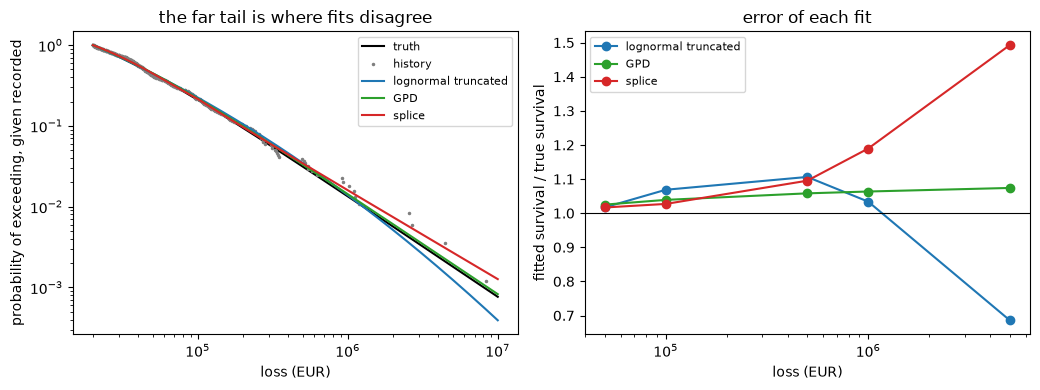

In [11]:
# Draw the survival of a recorded loss for the truth, the history and the three fits, and the error of each fit
fig, (left, right) = plt.subplots(1, 2, figsize=(10.5, 4.0))
x = np.logspace(np.log10(H), 7, 200)
left.loglog(
    x, 1.0 - distributions.truncated_severity_cdf("gpd", variant.sev_params, x, H), color="black", label="truth"
)
sorted_losses = np.sort(recorded.amounts)
empirical_sf = 1.0 - (np.arange(1, sorted_losses.size + 1) - 0.5) / sorted_losses.size
left.loglog(sorted_losses, empirical_sf, ".", color="tab:gray", markersize=3, label="history")
colors = {"lognormal truncated": "tab:blue", "GPD": "tab:green", "splice": "tab:red"}
for label, (law, params) in fits.items():
    left.loglog(x, 1.0 - distributions.truncated_severity_cdf(law, params, x, H), color=colors[label], label=label)
    right.semilogx(amounts, table[label] / table["truth"], "o-", color=colors[label], label=label)
left.set_xlabel("loss (EUR)")
left.set_ylabel("probability of exceeding, given recorded")
left.set_title("the far tail is where fits disagree")
left.legend(fontsize=8)
right.axhline(1.0, color="black", linewidth=0.8)
right.set_xlabel("loss (EUR)")
right.set_ylabel("fitted survival / true survival")
right.set_title("error of each fit")
right.legend(fontsize=8)
fig.tight_layout()
plt.show()

Up to about EUR 500,000 the three fits and the history lie on the truth: at EUR 100,000 the probabilities are 0.20994 in truth against 0.21813 for the generalised Pareto and 0.22436 for the truncated lognormal. The right panel shows where they part. At EUR 5,000,000, where ten years hold almost no observation, the truncated lognormal falls to 0.0012 against a true 0.0018 and the splice rises to 0.0027. The figure judges one history of one seed; it says nothing yet about how often a fit is defined at all.

### Step 8: the profile of the tail index across thresholds

If the generalised Pareto model were exact, the tail index fitted above any threshold would estimate the same number. `tail_index_profile` fits it at a list of thresholds; the case uses 1, 2, 4 and 8 times the collection threshold (Chavez-Demoulin, Embrechts and Neslehova, 2006). Fewer exceedances at higher thresholds make each fit noisier, so the profile is a trade between the bias of a low threshold and the variance of a high one. The engine test `oprisk.threshold_stability` summarises a profile by its **range** (maximum minus minimum of the finite tail indices) against two Contraste gates, 0.10 for green and 0.25 for amber; these are internal gates of the case, not regulatory thresholds. The next cell fits the profile of our history and runs the test, then prints the committed profile over 1,000 histories of the same cell (10 years, threshold EUR 20,000).

In [12]:
# Fit the tail-index profile of this history, run the stability test, and read the committed profile of the same cell
multiples = np.array([1.0, 2.0, 4.0, 8.0])
profile = distributions.tail_index_profile(recorded.amounts, H * multiples)
xi_profile = np.where(profile.converged, profile.xi, np.nan)
stability = oprisk_tests.threshold_stability(profile.thresholds, xi_profile, model_id="lda-splice")
cell = next(c for c in variants["xi-0-8"]["outputs"]["cells"] if c["id"] == "y10-h20000")
print("%12s %12s %8s %8s | committed over 1000 histories: p05, median, p95" % ("threshold", "exceedances", "xi", "se"))
for k, (u, n, xi_hat, se) in enumerate(zip(profile.thresholds, profile.n_exceedances, profile.xi, profile.xi_se)):
    row = cell["threshold_stability"][k]["tail_index"]
    print(
        "%12s %12d %8.4f %8.4f | %.3f %.3f %.3f" % (
            format(u, ",.0f"), n, xi_hat, se, row["p05"], row["median"], row["p95"]
        )
    )
print(
    "range of the profile:", round(stability.metric, 4), "| light:", stability.light.value, "| gates:",
    stability.extras["thresholds"]
)
print(
    "baked by riskvalidation", variants["xi-0-8"]["provenance"]["riskvalidation_version"], "| installed",
    md.version("riskvalidation")
)

   threshold  exceedances       xi       se | committed over 1000 histories: p05, median, p95
      20,000          422   0.8035   0.0862 | 0.646 0.799 0.940
      40,000          236   0.9138   0.1283 | 0.592 0.792 0.996
      80,000          118   0.8822   0.1707 | 0.492 0.786 1.054
     160,000           53   0.8736   0.2511 | 0.335 0.780 1.221
range of the profile: 0.1104 | light: amber | gates: {'tol_green': 0.1, 'tol_amber': 0.25}
baked by riskvalidation 1.0.1 | installed 1.0.1


The next cell draws the tail-index profile of this history with two-standard-error bars, on top of the 5% to 95% band the case committed over 1,000 histories and the true index.

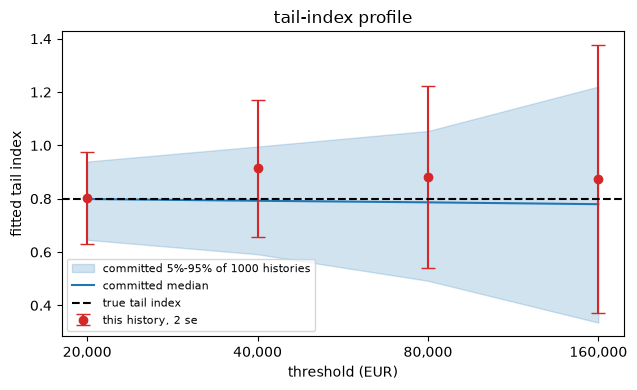

In [13]:
# Draw the tail-index profile of this history over the committed band of 1,000 histories
fig, ax = plt.subplots(figsize=(6.5, 4.0))
rows = cell["threshold_stability"]
ax.fill_between(range(4), [r["tail_index"]["p05"] for r in rows], [r["tail_index"]["p95"] for r in rows],
                color="tab:blue", alpha=0.2, label="committed 5%-95% of 1000 histories")
ax.plot(range(4), [r["tail_index"]["median"] for r in rows], color="tab:blue", label="committed median")
ax.errorbar(
    range(4), profile.xi, yerr=2 * profile.xi_se, fmt="o", color="tab:red", capsize=5, label="this history, 2 se"
)
ax.axhline(variant.tail_index, color="black", linestyle="--", label="true tail index")
ax.set_xticks(range(4))
ax.set_xticklabels([format(int(u), ",") for u in profile.thresholds])
ax.set_xlabel("threshold (EUR)")
ax.set_ylabel("fitted tail index")
ax.set_title("tail-index profile")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The red points stay near the true 0.80 at the lowest threshold, 0.8035 over 422 exceedances, and drift to 0.91, 0.88 and 0.87 as the threshold rises, while their bars widen because fewer losses remain. The shaded band explains why: over 1,000 histories the tail index fitted above EUR 160,000 ranges from 0.34 to 1.22, so a single high-threshold fit says little. The figure does not tell which threshold is right; it shows that the answer is stable enough only where many exceedances remain.

### Step 9: how stable are these fits?

One history is one draw. The committed documents record, for each rung of the ladder, on how many of the 1,000 histories of a cell it could be fitted. The next cell fits the truncated lognormal and the splice on twelve consecutive histories of the cell (seeds 4208000 to 4208011) and prints the lognormal parameters and the splice body weight, then the committed number of histories on which each rung is defined, for the four tail indices. A splice weight of 1 or a lognormal location far from the logarithm of the losses means the body of the fit has collapsed onto a degenerate law that the data cannot pin down.

In [14]:
# Fit the truncated lognormal and the splice on twelve consecutive histories, then read the committed counts of
# defined rungs
trials = []
for seed in range(4208000, 4208012):
    rec = generator.draw_history(variant, seed, YEARS).recorded(H)
    ln = distributions.fit_severity("lognormal", rec.amounts, H, truncated=True)
    sp = distributions.fit_splice(rec.amounts, H, SPLICE_AT)
    trials.append((seed, rec.amounts.size, ln.params[0], ln.params[1], sp.weight, sp.converged))
print("%8s %7s %10s %9s %9s %10s" % ("seed", "losses", "mu", "sigma", "w", "converged"))
for row in trials:
    print("%8d %7d %10.2f %9.3f %9.4f %10s" % row)
print("histories with a splice weight of 1:", sum(1 for row in trials if row[4] >= 0.9999), "of", len(trials))
print()
print("committed: histories (of 1000) where the rung is defined, cell y10-h20000")
RUNGS = ("lda_lognormal", "lda_lognormal_truncated", "lda_splice")
for name, doc in variants.items():
    cap = next(c for c in doc["outputs"]["cells"] if c["id"] == "y10-h20000")["capital"]
    blocks = {rung: cap[rung] if "n_defined" in cap[rung] else (cap[rung]["summary"] or {}) for rung in RUNGS}
    print("%-8s" % name, {rung: block.get("n_defined", 0) for rung, block in blocks.items()})

    seed  losses         mu     sigma         w  converged
 4208000     462      -3.11     3.830    1.0000      False
 4208001     422       6.37     2.190    1.0000       True
 4208002     422       5.80     2.512    0.8928       True
 4208003     447      -3.70     3.970    1.0000       True
 4208004     391       8.32     1.923    0.8524       True
 4208005     381       1.83     3.254    0.9003       True
 4208006     386       5.70     2.541    0.8984       True
 4208007     439       0.32     3.399    1.0000       True
 4208008     394 -354374.43   605.438    1.0000       True
 4208009     378      -4.27     4.035    0.9397       True
 4208010     412       2.84     3.031    0.9214       True
 4208011     423       6.50     2.272    0.9324       True
histories with a splice weight of 1: 5 of 12

committed: histories (of 1000) where the rung is defined, cell y10-h20000
xi-0-6   {'lda_lognormal': 1000, 'lda_lognormal_truncated': 1000, 'lda_splice': 859}
xi-0-8   {'lda_lognormal': 1

The next cell draws the twelve fits of the table above: the location of the truncated lognormal on a symmetric logarithmic axis, and the weight of the splice body.

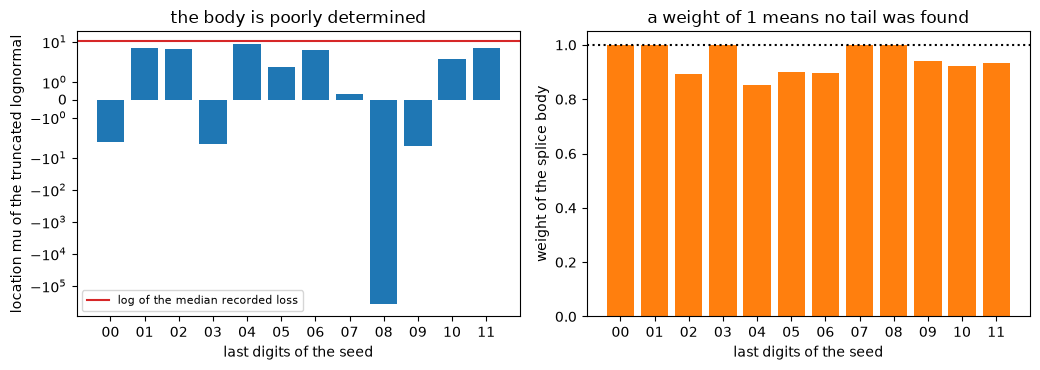

In [15]:
# Draw the lognormal location and the splice weight of the twelve histories
fig, (left, right) = plt.subplots(1, 2, figsize=(10.5, 3.8))
seeds = [str(row[0])[-2:] for row in trials]
left.bar(seeds, [row[2] for row in trials], color="tab:blue")
left.set_yscale("symlog")
left.axhline(np.log(np.median(recorded.amounts)), color="tab:red", label="log of the median recorded loss")
left.set_xlabel("last digits of the seed")
left.set_ylabel("location mu of the truncated lognormal")
left.set_title("the body is poorly determined")
left.legend(fontsize=8)
right.bar(seeds, [row[4] for row in trials], color="tab:orange")
right.axhline(1.0, color="black", linestyle=":")
right.set_xlabel("last digits of the seed")
right.set_ylabel("weight of the splice body")
right.set_title("a weight of 1 means no tail was found")
fig.tight_layout()
plt.show()

On the left, most bars sit far from the red line: the truncated lognormal puts its location anywhere from a large negative number to 8.32, while the recorded losses sit near 10.7 in logarithm. On the right, several bars touch 1, the splice's way of saying that the body swallowed the whole sample. These are not bugs of the engine: ten years of losses above a threshold simply do not pin a lognormal body down. The figure reads only twelve histories of one cell; the committed counts above give the size of the problem over 1,000.

## Results

**Answer:** From ten years the bank records 422 of its 673 losses, and the generalised Pareto fit recovers a tail index of 0.8035 (standard error 0.0862) against a true 0.80. The other fits are fragile: ignoring the threshold gives a median of EUR 57,379 where the recorded median is EUR 43,962, the truncated lognormal has a location with standard error 2.5993, and the tail-index profile ranges 0.1104 across thresholds, amber. Trust the generalised Pareto tail above the threshold and treat a lognormal body or a splice weight as unidentified.

- **The calibration.** Fitting only the scale, the largest absolute log error against the four LDCE percentiles is 0.447, 0.215, 0.038 and 0.160 for tail indices 0.6, 0.8, 0.96 and 1.1. The index near 0.96 is the one the percentiles themselves suggest, which is why the case runs a variant there, and the recomputation with the engine reproduces the recorded errors to four decimals.
- **What a bank records.** Of the 673 losses suffered in ten years, the bank records 422 above EUR 20,000. The Poisson rate is 42.2 a year with standard error 2.05, against a true 41.0.
- **Ignoring the threshold.** The lognormal fitted as if the recorded losses were all losses (mu 10.96, sigma 0.94) implies a median of EUR 57,379 where the sample median is EUR 43,962, and in the tail it is far too thin: the probability of a loss above EUR 500,000 is 0.0104 against 0.0379 recorded, above EUR 1,000,000 it is 0.0011 against a true 0.0134, and above EUR 5,000,000 it is zero to five decimals against 0.0018.
- **Modelling the threshold.** The truncated lognormal (mu 5.80 with standard error 2.60, sigma 2.51 with 0.55) has the higher log-likelihood, -5,064.9 against -5,195.2, and its median of EUR 44,298 matches the data. Its parameters are poorly determined, and the rescaled rate is 823 losses a year because only 5.1% of the fitted law lies above the threshold; the implied 71.97 losses a year above EUR 10,000 compare with a true 65.28.
- **The tail.** The generalised Pareto fit gives a tail index of 0.8035 with standard error 0.086, against a true 0.80. At EUR 5,000,000, where one history has hardly any observation, the probability of exceeding is 0.0018 in truth: the generalised Pareto gives 0.0020, the truncated lognormal undershoots it at 0.0012, and the splice, whose tail index is 0.911, overshoots it at 0.0027.
- **The profile.** The fitted tail index is 0.80, 0.91, 0.88 and 0.87 at thresholds EUR 20,000 to 160,000, a range of 0.110, which `oprisk.threshold_stability` colours amber (green needs 0.10 or less). Over 1,000 histories of the cell the median stays near 0.78 to 0.80 while the 5% to 95% band widens from 0.65 to 0.94 at the lowest threshold to 0.34 to 1.22 at the highest.
- **Stability.** On twelve consecutive histories the truncated lognormal location runs from -354,374 to 8.32, and the splice weight is exactly 1 in five of them, a sign that the body cannot be identified from losses above the threshold. The committed documents agree: at tail index 0.96 the truncated lognormal is defined on 723 of 1,000 histories of the cell and the splice on 572; at 1.1 on 205 and 409.

What this notebook does not show: how the fitted severities become a capital (notebook 03), the closed-form approximation (notebook 04), or the combination with expert scenarios (notebook 05).

## Summary

- A bank records only the losses above its collection threshold: fit a truncated severity and rescale the frequency by one over the survival at the threshold, or the capital is biased.
- Truncated fits of a heavy tail are poorly determined: a lognormal body can collapse, the splice weight can reach 1, and the rungs that need them are undefined on many histories.
- The tail-index profile and `oprisk.threshold_stability` read how the tail index drifts with the threshold; their gates are Contraste's own.
- The generator's tail index of 0.96 is the one closest to the four LDCE percentiles, and the case reads it as a variant, not as a finding about banks.

**What to try next.** Change `SEED` and `H` (10,000 against 20,000) and watch the number of recorded losses and the width of the profile. Then replace the splice threshold by EUR 50,000 and count how many of the twelve histories give a weight of 1. Continue with notebook 03.

## References

- BCBS (2009), Results from the 2008 Loss Data Collection Exercise for Operational Risk, Basel Committee on Banking Supervision. https://www.bis.org/publ/bcbs160.htm
- Chavez-Demoulin, V., Embrechts, P. and Neslehova, J. (2006), Quantitative models for operational risk: extremes, dependence and aggregation, Journal of Banking and Finance 30(10), 2635-2658. https://doi.org/10.1016/j.jbankfin.2005.11.008
- Mignola, G. and Ugoccioni, R. (2007), Effect of a data collection threshold in the loss distribution approach, Journal of Operational Risk 1(4), 35-47. https://doi.org/10.21314/JOP.2006.019